In [1]:
print("Importing...")
import sys
%load_ext autoreload
%autoreload 2
sys.path.insert(
    0,
    "/glade/u/home/manishrv/documents/nwa12_0.1/regional_mom_workflows/CrocoDash/CrocoDash/rm6",
)
import regional_mom6 as rm6 # type: ignore
from regional_mom6.utils import ap2ep, ep2ap # type: ignore
import xarray as xr
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
import numpy as np


Importing...


In [2]:
hgrid = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/2n3b.nwa-three-boundary-new-regridding/hgrid.nc")
coords = rm6.regridding.coords(hgrid, "north", "segment_002")
# Isolate the northern boundary, plot against the mask
tidal_data_given_angle = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing/tu_segment_002.nc")
tidal_data_fred = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/fred_average/forcing/tu_segment_002.nc")
tidal_data_keith = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/keith_double_regridding/forcing/tu_segment_002.nc")
tidal_data_keith_south = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/keith_double_regridding/forcing/tu_segment_001.nc")
tidal_data_keith_z= xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/keith_double_regridding/forcing/tz_segment_002.nc")

forcing_data_given_angle = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing_obc_segment_002.nc")
forcing_data_fred= xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/fred_average/forcing_obc_segment_002.nc")
forcing_data_keith = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/keith_double_regridding/forcing_obc_segment_002.nc")
forcing_data_keith_south = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/keith_double_regridding/forcing_obc_segment_001.nc")



2024-12-19 10:11:22,933 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary q/u/v points


In [5]:
tidal_data_keith_z.zamp_segment_002

<xarray.DataArray 'zamp_segment_002' (time: 1, constituent: 10,
                                      ny_segment_002: 1, nx_segment_002: 1481)> Size: 118kB
[14810 values with dtype=float64]
Coordinates:
    lon_segment_002  (nx_segment_002) float64 12kB ...
    lat_segment_002  (nx_segment_002) float64 12kB ...
  * time             (time) datetime64[ns] 8B 2000-01-01
Dimensions without coordinates: constituent, ny_segment_002, nx_segment_002

In [6]:
small_hgrid = hgrid.sel(nxp=slice(-100,-1),nyp=slice(-100,-1), ny=slice(-99,-1),nx=slice(-99,-1))

In [7]:
small_hgrid

<xarray.Dataset> Size: 468kB
Dimensions:   (nyp: 99, nxp: 99, ny: 98, nx: 98)
Dimensions without coordinates: nyp, nxp, ny, nx
Data variables:
    tile      |S255 255B ...
    y         (nyp, nxp) float64 78kB ...
    x         (nyp, nxp) float64 78kB ...
    dy        (ny, nxp) float64 78kB ...
    dx        (nyp, nx) float64 78kB ...
    area      (ny, nx) float64 77kB ...
    angle_dx  (nyp, nxp) float64 78kB ...
Attributes:
    file_name:    ocean_hgrid.nc
    Description:  MOM6 NCAR NWA12
    Author:       Fred Castruccio (fredc@ucar.edu)
    Created:      2024-04-18T08:39:49.607481
    type:         MOM6 supergrid file

In [8]:
small_hgrid.to_netcdf("small_curvilinear_hgrid.nc")

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

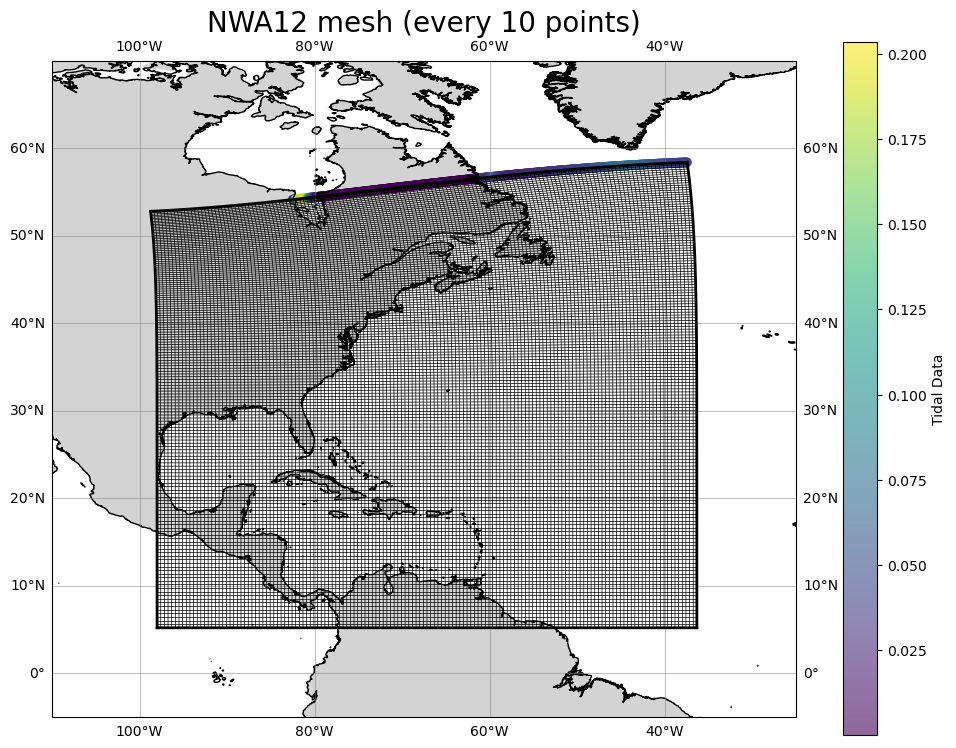

In [9]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_given_angle.lon_segment_002.values, tidal_data_given_angle.lat_segment_002.values, c= tidal_data_given_angle.uamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)



Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

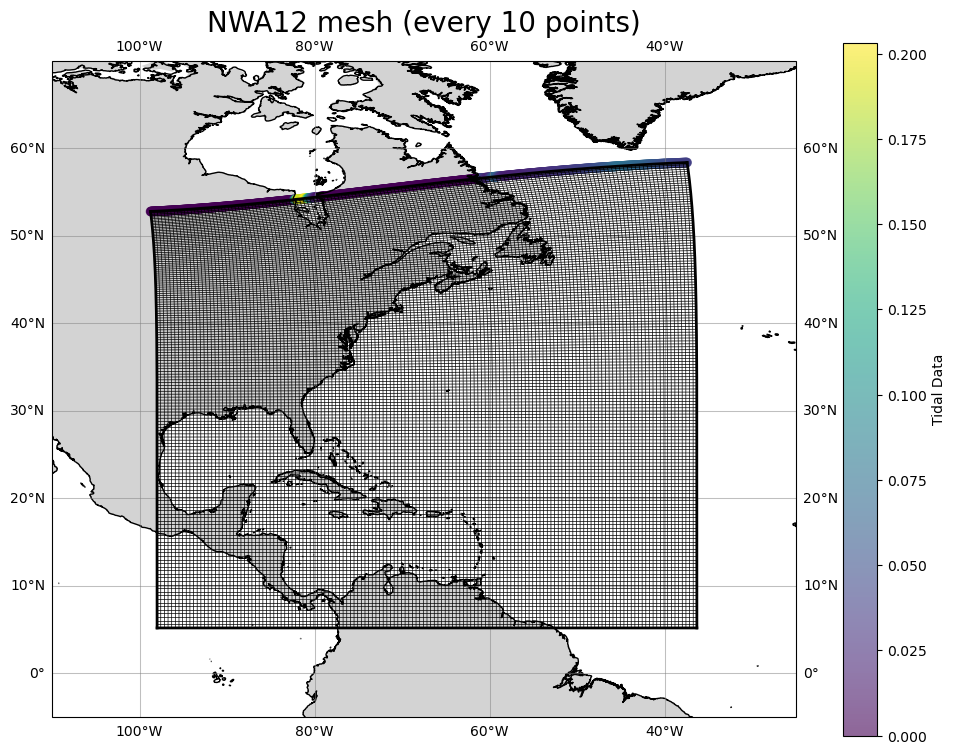

In [10]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_fred.lon_segment_002.values, tidal_data_fred.lat_segment_002.values, c= tidal_data_fred.uamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)


Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

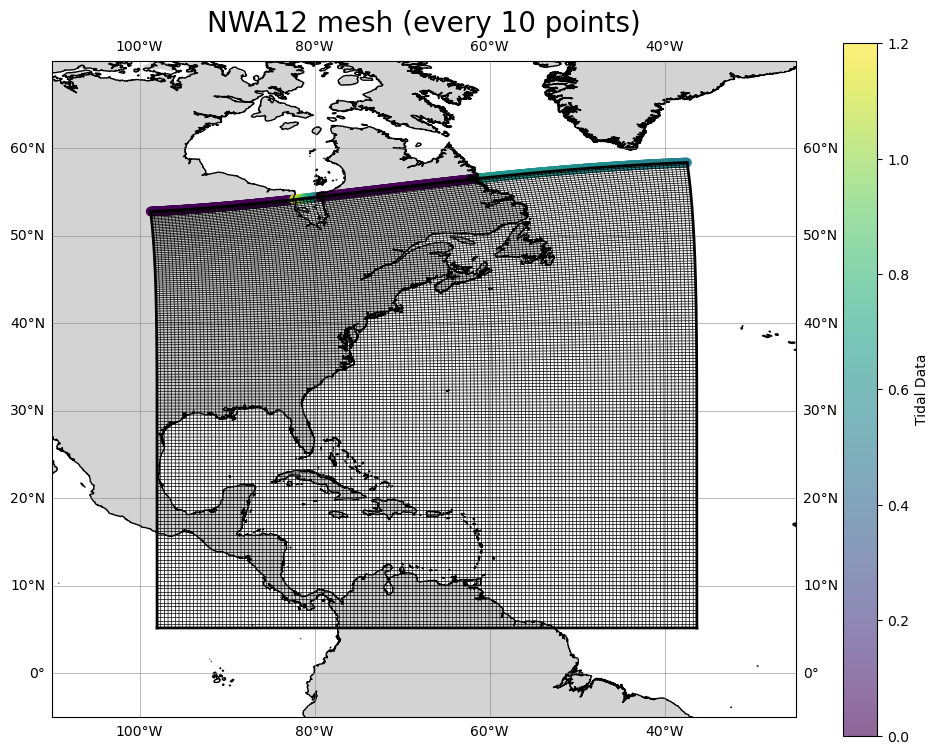

In [11]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_keith.lon_segment_002.values, tidal_data_keith.lat_segment_002.values, c= tidal_data_keith_z.zamp_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')




#scatter = ax.scatter(tidal_data_keith_south.lon_segment_001.values, tidal_data_keith_south.lat_segment_001.values, c= tu_1.uamp_segment_001[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)


In [12]:
tidal_data_keith.uamp_segment_002[0][0].values

array([[       nan,        nan,        nan, ..., 0.03802182, 0.03770623,
        0.03770623]], dtype=float32)

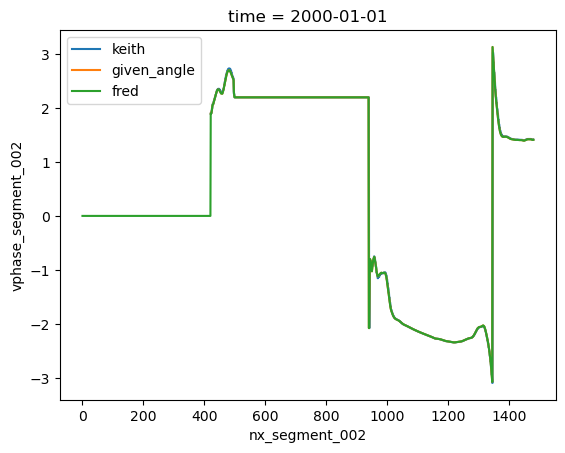

In [13]:
tidal_data_keith.vphase_segment_002[0][0].plot(label = "keith")
tidal_data_given_angle.vphase_segment_002[0][0].plot(label="given_angle")
tidal_data_fred.vphase_segment_002[0][0].plot(label="fred")
plt.legend()

In [14]:
tidal_data_given_angle.uamp_segment_002[0][0].data == tidal_data_fred.uamp_segment_002[0][0].data

array([[False, False, False, ..., False, False, False]])

In [15]:
tidal_data_keith

<xarray.Dataset> Size: 261kB
Dimensions:             (nx_segment_002: 1481, time: 1, constituent: 10,
                         ny_segment_002: 1)
Coordinates:
    nyp                 int64 8B ...
    lon_segment_002     (nx_segment_002) float64 12kB -98.75 -98.71 ... -37.45
    lat_segment_002     (nx_segment_002) float64 12kB 52.78 52.78 ... 58.38
  * time                (time) datetime64[ns] 8B 2000-01-01
Dimensions without coordinates: nx_segment_002, constituent, ny_segment_002
Data variables:
    uamp_segment_002    (time, constituent, ny_segment_002, nx_segment_002) float32 59kB ...
    vamp_segment_002    (time, constituent, ny_segment_002, nx_segment_002) float32 59kB ...
    uphase_segment_002  (time, constituent, ny_segment_002, nx_segment_002) float32 59kB ...
    vphase_segment_002  (time, constituent, ny_segment_002, nx_segment_002) float32 59kB ...

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

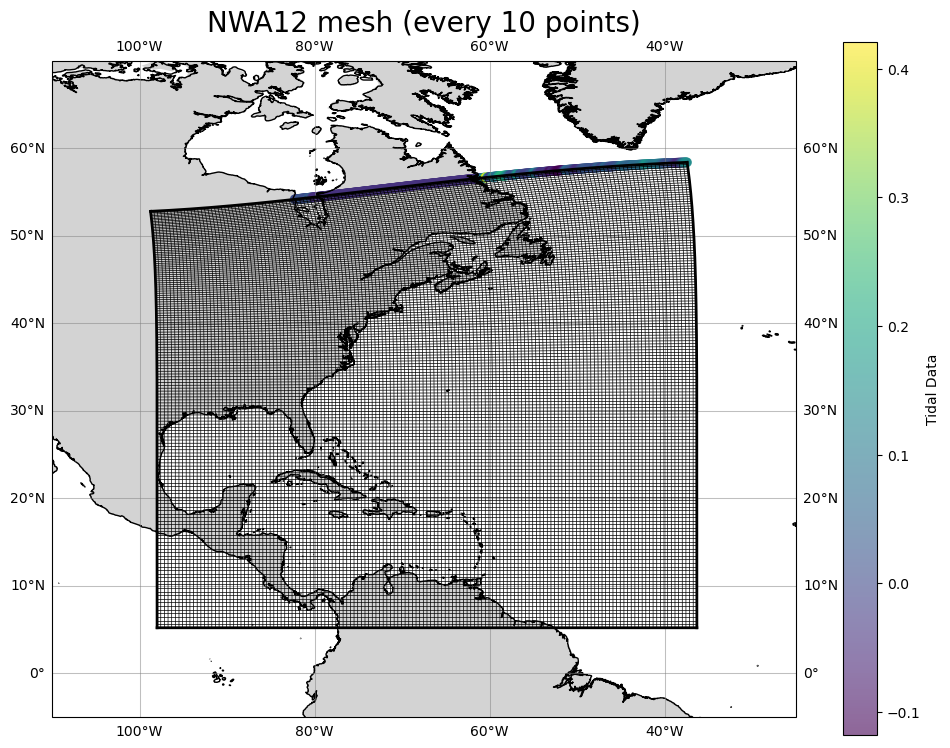

In [16]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_given_angle.lon_segment_002.values, tidal_data_given_angle.lat_segment_002.values, c= forcing_data_given_angle.u_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)
plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

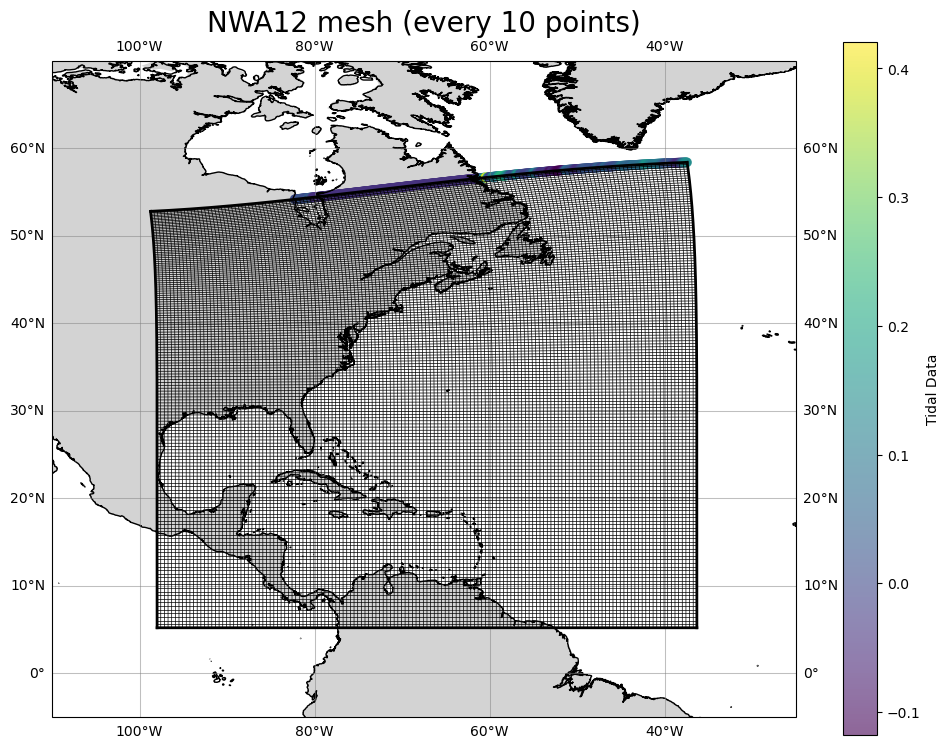

In [17]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_given_angle.lon_segment_002.values, tidal_data_given_angle.lat_segment_002.values, c= forcing_data_fred.u_segment_002[0][0], cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)

plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)

Text(0.5, 1.0, 'NWA12 mesh (every 10 points)')

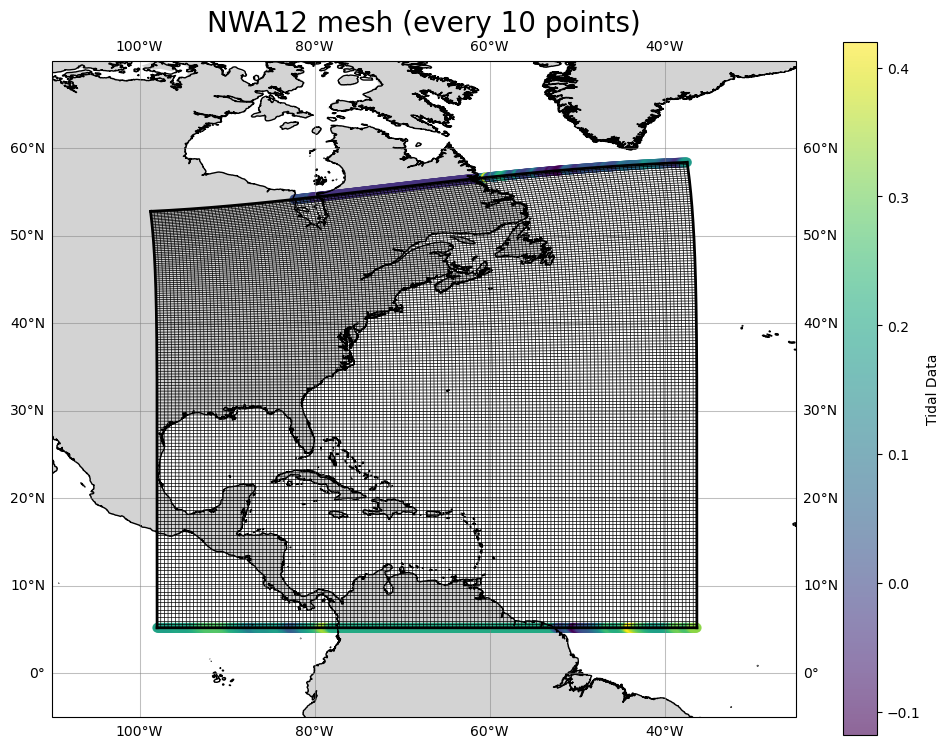

In [18]:
# Plot and save the NWA12 Mesh grid

plt.figure(figsize=(12,9))

# the central_longitude parameter tells the projection where to be centered for this axes
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-110, -25, -5, 70], ccrs.PlateCarree())
gl = ax.gridlines(linewidth=0.75, color='gray', alpha=0.5, linestyle='-', draw_labels=True)

# add geographic information
ax.add_feature(cartopy.feature.LAND, fc='lightgray')
#ax.add_feature(cartopy.feature.OCEAN)
ax.coastlines(resolution='10m')  # looks better with resolution='10m'
#ax.add_feature(cartopy.feature.BORDERS, linestyle='-', lw=.1)
#ax.add_feature(cartopy.feature.RIVERS)

k=10
ax.plot(hgrid.x[::k,::k], hgrid.y[::k,::k], color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())
ax.plot(hgrid.x[::k,::k].T, hgrid.y[::k,::k].T, color='k', ls='-', lw=.5, transform=ccrs.PlateCarree())

ax.plot(hgrid.x[0,:], hgrid.y[0,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[-1,:], hgrid.y[-1,:], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,0], hgrid.y[:,0], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
ax.plot(hgrid.x[:,-1], hgrid.y[:,-1], color='k', lw=2, ls='-', transform=ccrs.PlateCarree())
scatter = ax.scatter(tidal_data_given_angle.lon_segment_002.values, tidal_data_given_angle.lat_segment_002.values, c= forcing_data_keith.u_segment_002[0][0] , cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)

plt.colorbar(scatter, ax=ax, orientation='vertical', label='Tidal Data')
scatter = ax.scatter(tidal_data_keith_south.lon_segment_001.values, tidal_data_keith_south.lat_segment_001.values, c= forcing_data_keith_south.u_segment_001[0][0] , cmap='viridis', transform=ccrs.PlateCarree(), alpha=0.6)

plt.title('NWA12 mesh (every {} points)'.format(k), fontsize=20)

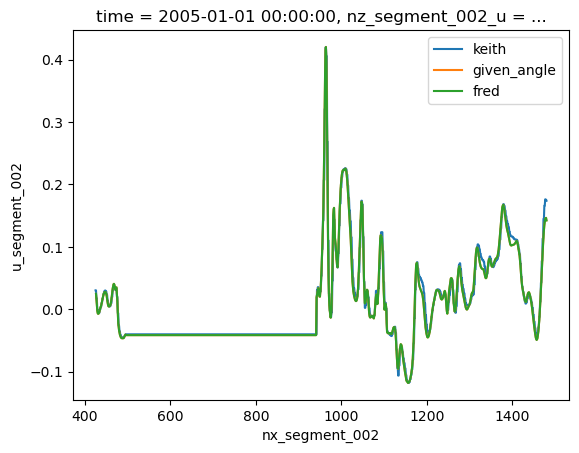

In [19]:
forcing_data_keith.u_segment_002[0][0].plot(label = "keith")
forcing_data_given_angle.u_segment_002[0][0].plot(label="given_angle")
forcing_data_fred.u_segment_002[0][0].plot(label="fred")
plt.legend()

In [20]:
np.where(np.isnan(forcing_data_keith.u_segment_002[0][0][0]))

(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
         13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
         26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
         39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
         52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
         65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
         78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
         91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
        104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
        117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
        130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
        143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
        156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
        169, 170, 171, 172, 173, 174, 175, 176, 177

In [21]:
np.where(np.isnan(tidal_data_keith.uphase_segment_002[0][0][0]))

(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
         13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
         26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
         39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
         52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
         65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
         78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
         91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
        104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
        117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
        130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
        143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
        156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
        169, 170, 171, 172, 173, 174, 175, 176, 177

In [12]:
bathy = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/angle_calc.2.2n3b/bathymetry.nc")


north_mask = rm6.regridding.get_boundary_mask(hgrid, bathy, "north", "segment_002")
south_mask = rm6.regridding.get_boundary_mask(hgrid, bathy, "south", "segment_001")
east_mask = rm6.regridding.get_boundary_mask(hgrid, bathy, "east", "segment_003")
new_east_mask = east_mask[ :, np.newaxis]


2024-12-18 14:50:02,376 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-18 14:50:02,390 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary t-points
2024-12-18 14:50:02,391 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-18 14:50:02,400 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary q/u/v points
2024-12-18 14:50:02,551 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-18 14:50:02,563 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary t-points
2024-12-18 14:50:02,563 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-18 14:50:02,572 - regional_mom6.regridding.coords - INFO - Creating coordinates of the boundary q/u/v points
2024-12-18 14:50:02,725 - regional_mom6.regridding.get_hgrid_arakawa_c_points - INFO - Getting t points..
2024-12-18

In [13]:
np.where(np.isnan(north_mask))

(array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
         14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
         27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
         40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
         53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
         66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
         79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
         92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
        105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
        118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
        131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
        144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
        157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
        170, 171, 172, 173, 174, 175, 176, 177, 178

In [72]:
np.where(np.isnan(north_mask))


(array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
         14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
         27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
         40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
         53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
         66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
         79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
         92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103, 104,
        105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117,
        118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130,
        131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143,
        144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156,
        157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169,
        170, 171, 172, 173, 174, 175, 176, 177, 178

In [16]:
tu_2 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing/tu_segment_002.nc")
tu_1 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing/tu_segment_001.nc")
tu_3 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing/tu_segment_003.nc")
tz_2 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing/tz_segment_002.nc")
tz_1 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing/tz_segment_001.nc")
tz_3 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing/tz_segment_003.nc")
f_1 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing_obc_segment_001.nc")
f_2 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing_obc_segment_002.nc")
f_3 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/forcing_obc_segment_003.nc")


In [74]:
for var in f_1.data_vars.keys():
    f_1[var] = f_1[var].fillna(0)
    f_1[var] = f_1[var]*south_mask
for var in f_2.data_vars.keys():
    f_2[var] = f_2[var].fillna(0)
    f_2[var] = f_2[var]*north_mask
for var in f_3.data_vars.keys():
    f_3[var] = f_3[var].fillna(0)
    f_3[var] = f_3[var]*new_east_mask
for var in tu_1.data_vars.keys():
    tu_1[var] = tu_1[var].fillna(0)
    tu_1[var] = tu_1[var]*south_mask
for var in tu_2.data_vars.keys():
    tu_2[var] = tu_2[var].fillna(0)
    tu_2[var] = tu_2[var]*north_mask
for var in tu_3.data_vars.keys():
    tu_3[var] = tu_3[var].fillna(0)
    tu_3[var] = tu_3[var]*new_east_mask
for var in tz_1.data_vars.keys():
    tz_1[var] = tz_1[var].fillna(0)
    tz_1[var] = tz_1[var]*south_mask
for var in tz_2.data_vars.keys():
    tz_2[var] = tz_2[var].fillna(0)
    tz_2[var] = tz_2[var]*north_mask
for var in tz_3.data_vars.keys():
    tz_3[var] = tz_3[var].fillna(0)
    tz_3[var] = tz_3[var]*new_east_mask

In [44]:
encoding_tu_2 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_002": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_002": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_2 = rm6.regridding.generate_encoding(
    tu_2, encoding_tu_2, default_fill_value = 1.0e20
)
encoding_tz_2 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_002": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_002": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_2 = rm6.regridding.generate_encoding(
    tz_2, encoding_tz_2, default_fill_value = 1.0e20
)
encoding_dict_f_2 = {
    "time": {"dtype": "double"},
    f"nx_segment_002": {
        "dtype": "int32",
    },
    f"ny_segment_002": {
        "dtype": "int32",
    },
}
encoding_dict_f_2 = rm6.regridding.generate_encoding(
    f_2,
    encoding_dict_f_2,
    default_fill_value=1.0e20,
)

encoding_tu_3 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_003": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_003": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_3 = rm6.regridding.generate_encoding(
    tu_3, encoding_tu_3, default_fill_value = 1.0e20
)
encoding_tz_3 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_003": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_003": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_3 = rm6.regridding.generate_encoding(
    tz_3, encoding_tz_3, default_fill_value = 1.0e20
)
encoding_dict_f_3 = {
    "time": {"dtype": "double"},
    f"nx_segment_003": {
        "dtype": "int32",
    },
    f"ny_segment_003": {
        "dtype": "int32",
    },
}
encoding_dict_f_3 = rm6.regridding.generate_encoding(
    f_3,
    encoding_dict_f_3,
    default_fill_value=1.0e20,
)

encoding_tu_1 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_001": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_001": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_1 = rm6.regridding.generate_encoding(
    tu_1, encoding_tu_1, default_fill_value = 1.0e20
)
encoding_tz_1 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_001": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_001": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_1 = rm6.regridding.generate_encoding(
    tz_1, encoding_tz_1, default_fill_value = 1.0e20
)
encoding_dict_f_1 = {
    "time": {"dtype": "double"},
    f"nx_segment_001": {
        "dtype": "int32",
    },
    f"ny_segment_001": {
        "dtype": "int32",
    },
}
encoding_dict_f_1 = rm6.regridding.generate_encoding(
    f_1,
    encoding_dict_f_1,
    default_fill_value=1.0e20,
)

2024-12-17 17:34:31,423 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-17 17:34:31,424 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-17 17:34:31,424 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-17 17:34:31,428 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-17 17:34:31,428 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-17 17:34:31,429 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-17 17:34:31,430 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-17 17:34:31,430 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-17 17:34:31,431 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary


In [76]:

tu_2.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/tu_segment_002.nc", encoding=encoding_tu_2,
            unlimited_dims="time")
tz_2.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/tz_segment_002.nc", encoding=encoding_tz_2,
            unlimited_dims="time")
f_2.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/forcing_obc_segment_002.nc", encoding=encoding_dict_f_2,
            unlimited_dims="time")


In [51]:
tu_2.uamp_segment_002[0][0].values

array([[       nan,        nan,        nan, ..., 0.03793384, 0.03775294,
        0.03756352]])

In [77]:
f_3.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/forcing_obc_segment_003.nc", encoding=encoding_dict_f_3,
            unlimited_dims="time")
tz_3.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/tz_segment_003.nc", encoding=encoding_tz_3,
            unlimited_dims="time")
tu_3.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/tu_segment_003.nc", encoding=encoding_tu_3,
            unlimited_dims="time")


In [78]:
tu_1.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/tu_segment_001.nc", encoding=encoding_tu_1,
            unlimited_dims="time")
f_1.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/forcing_obc_segment_001.nc", encoding=encoding_dict_f_1,
            unlimited_dims="time")
tz_1.to_netcdf("/glade/u/home/manishrv/documents/nwa12_0.1/tides_dev/outputs/given_angle/adjusted_forcing/tz_segment_001.nc", encoding=encoding_tz_1,
            unlimited_dims="time")


In [33]:
import xarray as xr
tu_2 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/angle_calc.1.2n3b/temp_stor_working/tu_segment_002.nc")
tz_2 = xr.open_dataset("/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/angle_calc.1.2n3b/temp_stor_working/tz_segment_002.nc")
north_mask = ~(np.isnan(tu_2.uamp_segment_002[0][0].values))
north_mask =np.where(north_mask, north_mask, np.nan)

In [8]:
ocean_geo = xr.open_dataset("/glade/u/home/manishrv/manish_scratch_symlink/angle_calc.1.2n3b/run/ocean_geometry.nc")
ocean_static = xr.open_dataset("//glade/u/home/manishrv/manish_scratch_symlink/2n3b.Gio.freeze/run/ocean_static.nc")

ocean_static

<xarray.Dataset> Size: 56MB
Dimensions:       (xh: 740, yh: 780, time: 1, xq: 741, yq: 781)
Coordinates:
  * xh            (xh) float64 6kB -97.96 -97.88 -97.79 ... -36.54 -36.46 -36.38
  * yh            (yh) float64 6kB 5.243 5.326 5.409 5.492 ... 53.82 53.86 53.89
  * time          (time) object 8B 2003-01-01 00:00:00
  * xq            (xq) float64 6kB -98.0 -97.92 -97.83 ... -36.5 -36.42 -36.33
  * yq            (yq) float64 6kB 5.201 5.284 5.367 5.45 ... 53.84 53.87 53.91
Data variables: (12/24)
    areacello     (yh, xh) float32 2MB ...
    deptho        (yh, xh) float32 2MB ...
    Coriolis      (yq, xq) float32 2MB ...
    geolon        (yh, xh) float32 2MB ...
    geolat        (yh, xh) float32 2MB ...
    geolon_c      (yq, xq) float32 2MB ...
    ...            ...
    dyCu          (yh, xq) float32 2MB ...
    dxCv          (yq, xh) float32 2MB ...
    dyCv          (yq, xh) float32 2MB ...
    areacello_cu  (yh, xq) float32 2MB ...
    areacello_cv  (yq, xh) float32 2MB ...
    areacello_bu  (yq, xq) float32 2MB ...
Attributes:
    NumFilesInSet:  1
    title:          mom6-regional
    grid_type:      regular
    grid_tile:      N/A

In [14]:

np.where(ocean_static.wet_u[-1] == 0)

(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
         13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
         26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
         39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
         52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
         65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
         78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
         91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
        104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
        117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
        130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
        143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
        156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
        169, 170, 171, 172, 173, 174, 175, 176, 177

In [17]:
path = "/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/angle_calc.1.2n3b/"
adjusted_path = "/glade/u/home/manishrv/documents/nwa12_0.1/mom_input/angle_calc.2.2n3b/adjusted_forcing/"
datasets = ["tz_segment_003.nc",
            "tz_segment_002.nc",
            "tz_segment_001.nc",
            "tu_segment_003.nc",
            "tu_segment_002.nc",
            "tu_segment_001.nc",
            "forcing_obc_segment_003.nc",
            "forcing_obc_segment_002.nc",
            "forcing_obc_segment_001.nc"]

In [18]:
encoding_tu_2 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_002": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_002": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_2 = rm6.regridding.generate_encoding(
    tu_2, encoding_tu_2, default_fill_value = 1.0e20
)
encoding_tz_2 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_002": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_002": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_2 = rm6.regridding.generate_encoding(
    tz_2, encoding_tz_2, default_fill_value = 1.0e20
)
encoding_dict_f_2 = {
    "time": {"dtype": "double"},
    f"nx_segment_002": {
        "dtype": "int32",
    },
    f"ny_segment_002": {
        "dtype": "int32",
    },
}
encoding_dict_f_2 = rm6.regridding.generate_encoding(
    f_2,
    encoding_dict_f_2,
    default_fill_value=1.0e20,
)

encoding_tu_3 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_003": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_003": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_3 = rm6.regridding.generate_encoding(
    tu_3, encoding_tu_3, default_fill_value = 1.0e20
)
encoding_tz_3 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_003": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_003": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_3 = rm6.regridding.generate_encoding(
    tz_3, encoding_tz_3, default_fill_value = 1.0e20
)
encoding_dict_f_3 = {
    "time": {"dtype": "double"},
    f"nx_segment_003": {
        "dtype": "int32",
    },
    f"ny_segment_003": {
        "dtype": "int32",
    },
}
encoding_dict_f_3 = rm6.regridding.generate_encoding(
    f_3,
    encoding_dict_f_3,
    default_fill_value=1.0e20,
)

encoding_tu_1 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_001": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_001": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tu_1 = rm6.regridding.generate_encoding(
    tu_1, encoding_tu_1, default_fill_value = 1.0e20
)
encoding_tz_1 = {
    "time": dict(dtype="float64", calendar="gregorian", _FillValue=1.0e20),
    f"lon_segment_001": dict(dtype="float64", _FillValue=1.0e20),
    f"lat_segment_001": dict(dtype="float64", _FillValue=1.0e20),
}
encoding_tz_1 = rm6.regridding.generate_encoding(
    tz_1, encoding_tz_1, default_fill_value = 1.0e20
)
encoding_dict_f_1 = {
    "time": {"dtype": "double"},
    f"nx_segment_001": {
        "dtype": "int32",
    },
    f"ny_segment_001": {
        "dtype": "int32",
    },
}
encoding_dict_f_1 = rm6.regridding.generate_encoding(
    f_1,
    encoding_dict_f_1,
    default_fill_value=1.0e20,
)

2024-12-18 15:13:05,242 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-18 15:13:05,243 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-18 15:13:05,244 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-18 15:13:05,244 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-18 15:13:05,245 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-18 15:13:05,246 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-18 15:13:05,246 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-18 15:13:05,247 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary
2024-12-18 15:13:05,247 - regional_mom6.regridding.generate_encoding - INFO - Generating encoding dictionary


In [20]:
north_big_q_mask = np.full(north_mask.shape,0.0)
north_big_q_mask[0] = np.nan
north_big_q_mask[-1] = 1
big_east_mask = np.full(east_mask.shape,0)
# big_east_mask[0] = 100
# big_east_mask[-1] = 100
big_east_mask = big_east_mask[:, np.newaxis]
for ds_path in datasets:
    ds = xr.open_dataset(path+ds_path)
    for var in ds.data_vars.keys():
        if "003" in var:
                
            ds[var]=ds[var]+big_east_mask
            ds[var]=ds[var]+big_east_mask
        else:
            ds[var]=ds[var]+north_big_q_mask
            ds[var]=ds[var]+north_big_q_mask
    if "tz" in ds_path and "003" in ds_path:
        encoding_dict = encoding_tz_3
    elif "tu" in ds_path and "003" in ds_path:
        encoding_dict = encoding_tu_3
    elif "forcing" in ds_path and "003" in ds_path:
        encoding_dict = encoding_dict_f_3
    elif "tz" in ds_path and "002" in ds_path:
        encoding_dict = encoding_tz_2
    elif "tu" in ds_path and "002" in ds_path:
        encoding_dict = encoding_tu_2
    elif "forcing" in ds_path and "002" in ds_path:
        encoding_dict = encoding_dict_f_2
    elif "tz" in ds_path and "001" in ds_path:
        encoding_dict = encoding_tz_1
    elif "tu" in ds_path and "001" in ds_path:
        encoding_dict = encoding_tu_1
    elif "forcing" in ds_path and "001" in ds_path:
        encoding_dict = encoding_dict_f_1
    ds.to_netcdf(adjusted_path+ds_path, encoding=encoding_dict,
            unlimited_dims="time")

In [4]:
ocean_static_obc = xr.open_dataset("/glade/u/home/manishrv/ocean_static.nc")
ocean_static_obc


<xarray.Dataset> Size: 65MB
Dimensions:       (xh: 740, yh: 780, time: 1, xq: 741, yq: 781)
Coordinates:
  * xh            (xh) float64 6kB -97.96 -97.88 -97.79 ... -36.54 -36.46 -36.38
  * yh            (yh) float64 6kB 5.243 5.326 5.409 5.492 ... 53.82 53.86 53.89
  * time          (time) object 8B 2003-01-01 00:00:00
  * xq            (xq) float64 6kB -98.0 -97.92 -97.83 ... -36.5 -36.42 -36.33
  * yq            (yq) float64 6kB 5.201 5.284 5.367 5.45 ... 53.84 53.87 53.91
Data variables: (12/28)
    areacello     (yh, xh) float32 2MB ...
    deptho        (yh, xh) float32 2MB ...
    Coriolis      (yq, xq) float32 2MB ...
    geolon        (yh, xh) float32 2MB ...
    geolat        (yh, xh) float32 2MB ...
    geolon_c      (yq, xq) float32 2MB ...
    ...            ...
    dyCu          (yh, xq) float32 2MB ...
    dxCv          (yq, xh) float32 2MB ...
    dyCv          (yq, xh) float32 2MB ...
    areacello_cu  (yh, xq) float32 2MB ...
    areacello_cv  (yq, xh) float32 2MB ...
    areacello_bu  (yq, xq) float32 2MB ...
Attributes:
    NumFilesInSet:  1
    title:          mom6-regional
    grid_type:      regular
    grid_tile:      N/A

In [24]:
np.where(ocean_static_obc["wet_c"][-1].values==0)

(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
         13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
         26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
         39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
         52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
         65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
         78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
         91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
        104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
        117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
        130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
        143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
        156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
        169, 170, 171, 172, 173, 174, 175, 176, 177

In [11]:
469*2 + 1

939